# Anti-resonances

Drive a linear system at one point and watch the response at another. The
magnitude of the frequency response function (FRF) shows **resonances**,
sharp peaks where the drive excites a mode, and often also
**anti-resonances**, sharp dips where the response nearly vanishes although
the drive keeps going.

The FRF of a system with finitely many modes is a rational function,

$$
H_{ij}(\Omega) = \frac{N_{ij}(\Omega)}{D(\Omega)}
             = \sum_k \frac{r_{ij,k}}{\Omega - \omega_k}.
$$

* The resonances are the zeros of the denominator, the **poles**
  $\omega_k$. They are the same for every pair of drive point $j$ and
  response point $i$.
* The anti-resonances are the zeros of the numerator $N_{ij}$. They
  depend on where you drive and where you look: where neighbouring
  modal contributions $r_k / (\Omega - \omega_k)$ have opposite signs they
  cancel.

Harmonic inversion fits the impulse response with damped exponentials,
$c(t) = \sum_k d_k e^{-i\omega_k t}$, so what it finds are poles. An
anti-resonance leaves no oscillation of its own in the time signal, and
never shows up as a mode. But the fitted frequencies *and* amplitudes
define the whole rational spectrum, and with it its zeros:
`HarmInvResult.zeros()` returns them. This notebook shows how that works,
what the zeros mean physically, and where the pitfalls are.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pyharminv import harminv

plt.rcParams["figure.figsize"] = (9, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. A model system

Three masses in a chain, fixed to a wall at the left end, with light
proportional (Rayleigh) damping $C = \alpha M + \beta K$:

```
wall —k1— m1 —k2— m2 —k3— m3
```

The exact FRF follows from $H(\Omega) = (K - \Omega^2 M - i\Omega C)^{-1}$
(with the $e^{-i\omega t}$ convention used throughout pyharminv), and the
impulse responses from the eigenvalues of the first-order system.

exact modes: [0.4868-0.0025j 1.5266-0.0067j 2.3307-0.0129j]


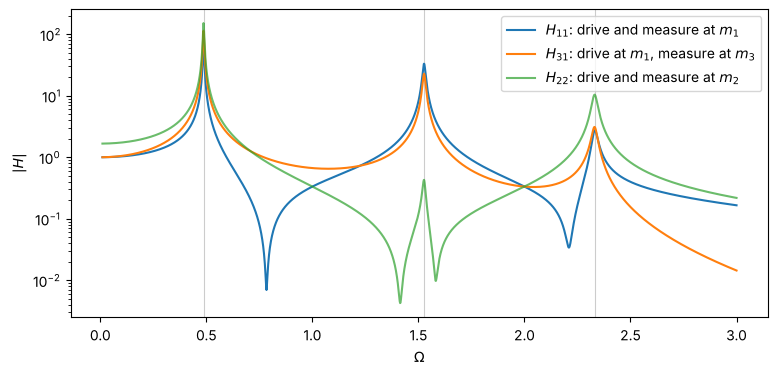

In [2]:
masses = np.array([1.0, 1.0, 1.0])
springs = np.array([1.0, 1.5, 2.0])
n = len(masses)
M = np.diag(masses)
K = np.diag(springs + np.append(springs[1:], 0)) - np.diag(springs[1:], 1) - np.diag(springs[1:], -1)
C = 0.004 * M + 0.004 * K

def frf(Omega, M=M, C=C, K=K):
    # H[i, j](Omega): displacement at i per unit force at j
    return np.array([np.linalg.inv(K - w**2 * M - 1j * w * C) for w in Omega])

def eigenfrequencies(M, C, K):
    # complex omega with Re(omega) > 0, omega = i s for M s^2 + C s + K
    m = len(M)
    A = np.block([[np.zeros((m, m)), np.eye(m)],
                  [-np.linalg.solve(M, K), -np.linalg.solve(M, C)]])
    w = 1j * np.linalg.eigvals(A)
    return np.sort_complex(w[w.real > 0])

def impulse_response(i, j, t):
    # displacement at i after a unit impulse force at j
    A = np.block([[np.zeros((n, n)), np.eye(n)],
                  [-np.linalg.solve(M, K), -np.linalg.solve(M, C)]])
    lam, V = np.linalg.eig(A)
    b = np.zeros(2 * n)
    b[n:] = np.linalg.solve(M, np.eye(n)[j])
    return (np.exp(np.outer(t, lam)) @ (V[i] * np.linalg.solve(V, b))).real

modes_exact = eigenfrequencies(M, C, K)
print("exact modes:", modes_exact)

Omega = np.linspace(0.01, 3, 3000)
H = frf(Omega)
fig, ax = plt.subplots()
ax.semilogy(Omega, abs(H[:, 0, 0]), label="$H_{11}$: drive and measure at $m_1$")
ax.semilogy(Omega, abs(H[:, 2, 0]), label="$H_{31}$: drive at $m_1$, measure at $m_3$")
ax.semilogy(Omega, abs(H[:, 1, 1]), label="$H_{22}$: drive and measure at $m_2$", alpha=0.7)
for w in modes_exact.real:
    ax.axvline(w, color="0.8", lw=0.8, zorder=0)
ax.set_xlabel(r"$\Omega$"); ax.set_ylabel("$|H|$"); ax.legend();

All three curves peak at the same three frequencies (grey lines). The
dips differ:

* The **driving-point** FRFs $H_{11}$ and $H_{22}$ have exactly one
  anti-resonance between every pair of neighbouring resonances. For a
  collocated drive and response all residues have the same sign, so the
  terms of neighbouring modes always cancel somewhere in between.
  Resonances and anti-resonances alternate.
* The **transfer** FRF $H_{31}$, from one end of the chain to the other,
  has no anti-resonance at all. Its residues alternate in sign, and the
  modal contributions add up between the peaks instead of cancelling.

## 2. Anti-resonances from harmonic inversion

We now pretend we only have the measured impulse response at $m_1$ after
a hammer blow at $m_1$, and run harmonic inversion on it.

In [3]:
dt = 0.25
t = dt * np.arange(2000)
h11 = impulse_response(0, 0, t)

res = harminv(h11, dt, omega_min=0.05, omega_max=4)
print(res)
print("\nanti-resonances:", res.zeros())

HarmInvResult with 3 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
     0.4867767   -0.002473915      98.38      0.3311   1.5708   3.8e-14
      1.526577   -0.006660966      114.6      0.4425   1.5708   1.9e-14
       2.33075    -0.01286512      90.58     0.07011   1.5708   4.9e-14

anti-resonances: [0.7836-0.0032j 2.2104-0.0118j]


`zeros()` returns complex numbers, like the mode frequencies:
$\mathrm{Re}\,z$ is the position of the dip and $-2\,\mathrm{Im}\,z$ its
width (the dip is an inverted Lorentzian, as deep and narrow as damping
allows).

What do these numbers mean physically? At an anti-resonance of $H_{jj}$
the drive point $j$ stands still while the rest of the structure keeps
oscillating. That is exactly a mode of the structure with point $j$
clamped. So the anti-resonances of $H_{11}$ must be the eigenfrequencies
of the two-mass chain that remains when $m_1$ is held fixed:

In [4]:
def clamped(j):
    keep = [k for k in range(n) if k != j]
    return eigenfrequencies(*(X[np.ix_(keep, keep)] for X in (M, C, K)))

print("zeros from harminv  :", res.zeros())
print("m1 clamped, exact   :", clamped(0))
print("difference          :", abs(res.zeros() - clamped(0)))

zeros from harminv  : [0.7836-0.0032j 2.2104-0.0118j]
m1 clamped, exact   : [0.7836-0.0032j 2.2104-0.0118j]
difference          : [0. 0.]


They agree to machine precision, damping included. The same works for
the other driving points, and the transfer FRF correctly yields no zeros:

In [5]:
for (i, j) in [(1, 1), (2, 2), (2, 0)]:
    r = harminv(impulse_response(i, j, t), dt, omega_min=0.05, omega_max=4)
    exact = clamped(j) if i == j else "none"
    print(f"H{i+1}{j+1}: zeros {r.zeros()}   exact {exact}")

H22: zeros [1.4142-0.006j 1.5811-0.007j]   exact [1.4142-0.006j 1.5811-0.007j]


H33: zeros [1.1911-0.0048j 2.1403-0.0112j]   exact [1.1911-0.0048j 2.1403-0.0112j]


H31: zeros []   exact none


`res.spectrum(Omega)` evaluates the fitted rational spectrum. For a real
impulse response it is the complex conjugate of the FRF, so its
magnitude is $|H|$:

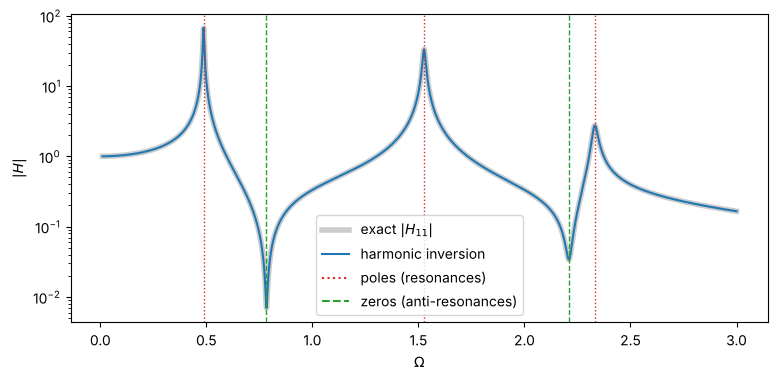

In [6]:
fig, ax = plt.subplots()
ax.semilogy(Omega, abs(H[:, 0, 0]), lw=4, color="0.8", label="exact $|H_{11}|$")
ax.semilogy(Omega, abs(res.spectrum(Omega)), label="harmonic inversion")
for w in res.center:
    ax.axvline(w, color="C3", ls=":", lw=1)
for z in res.zeros():
    ax.axvline(z.real, color="C2", ls="--", lw=1)
ax.plot([], [], "C3:", label="poles (resonances)")
ax.plot([], [], "C2--", label="zeros (anti-resonances)")
ax.set_xlabel(r"$\Omega$"); ax.set_ylabel("$|H|$"); ax.legend();

## 3. A realistic case: short, noisy record

Experimentally, the FRF is often obtained by Fourier transforming a
measured response. Dips are much harder to measure than peaks: they are
easily filled in by noise, and with a short record the leakage of the
neighbouring peaks smears them out completely. Harmonic inversion does
not need to see the dip. It only has to get the poles and amplitudes
right, which it does from a short record, and the zeros follow.

Here we take only 60 time units of the response (the lowest mode decays
on a time scale of 400) with 1 % noise.

HarmInvResult with 3 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
     0.4867883   -0.002465558      98.72       0.331   1.5704   6.1e-06
      1.526607    -0.00668747      114.1       0.443   1.5705   2.7e-06
      2.330284     -0.0126655      91.99      0.0698   1.5627   1.7e-05

zeros from noisy data: [0.7834-0.0033j 2.2106-0.0109j]
exact                : [0.7836-0.0032j 2.2104-0.0118j]


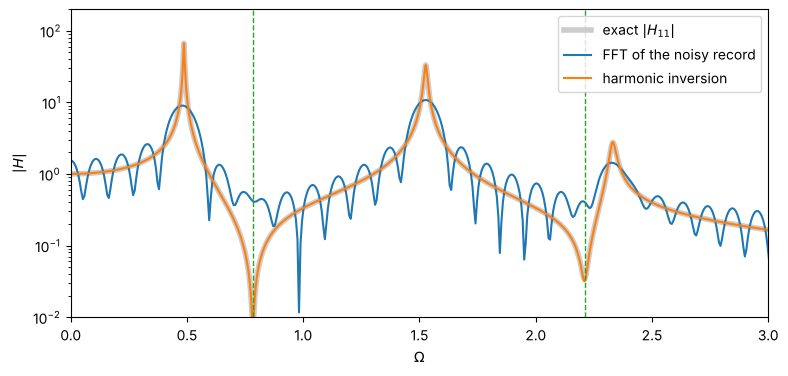

In [7]:
rng = np.random.default_rng(1)
dt = 0.25
t_short = dt * np.arange(240)
h = impulse_response(0, 0, t_short)
noise = 0.01 * np.sqrt(np.mean(h**2))
h_noisy = h + noise * rng.standard_normal(len(h))

res_noisy = harminv(h_noisy, dt, omega_min=0.05, omega_max=4, tol=0.01)
res_noisy = res_noisy.select(min_magnitude=0.05 * res_noisy.magnitude.max())
print(res_noisy)
print("\nzeros from noisy data:", res_noisy.zeros())
print("exact                :", clamped(0))

# what a plain FFT of the record gives (zero padded for a smooth curve)
nfft = 16 * len(h_noisy)
fft_spec = dt * np.fft.rfft(h_noisy, nfft)
fft_omega = 2 * np.pi * np.fft.rfftfreq(nfft, dt)

fig, ax = plt.subplots()
ax.semilogy(Omega, abs(H[:, 0, 0]), lw=4, color="0.8", label="exact $|H_{11}|$")
ax.semilogy(fft_omega, abs(fft_spec), label="FFT of the noisy record")
ax.semilogy(Omega, abs(res_noisy.spectrum(Omega)), label="harmonic inversion")
for z in res_noisy.zeros():
    ax.axvline(z.real, color="C2", ls="--", lw=1)
ax.set_xlim(0, 3); ax.set_ylim(1e-2, 2e2)
ax.set_xlabel(r"$\Omega$"); ax.set_ylabel("$|H|$"); ax.legend();

The FFT of the short record shows neither the height of the peaks nor
the anti-resonances: the true dips are buried under the leakage of the
peaks, and the sidelobes of the truncated record produce many false
dips instead. Harmonic inversion recovers peaks and dips, and the zeros
agree with the exact ones to a few parts in $10^4$ in position.

## 4. Pitfall: zeros depend on *all* modes

A pole is a local property: harmonic inversion finds it from the part of
the signal near its frequency, which is why pyharminv can work in
frequency windows. A zero is not. It is where the contributions of
*all* modes cancel, including modes far outside the analysed range. A
mode above the band adds a nearly constant background (a "residual") to
the spectrum near the zero, a mode below the band a background falling
off with frequency, and leaving them out shifts the zeros.

Say we only analyse the band below $\Omega = 2$ and so miss the third
mode:

In [8]:
low = res.select(omega_max=2)
print("first zero, all modes      :", res.zeros()[0])
print("first zero, two modes only :", low.zeros()[0])

first zero, all modes      : (0.7835742745260653-0.0032279981273092254j)
first zero, two modes only : (0.8001388209910355-0.0032804657885684486j)


The anti-resonance moves by 2 %, many times its width. The cure from
experimental modal analysis is a residual term: approximate the
contribution of the missing modes by a constant near the zero of
interest. `zeros(residual=...)` adds that constant to the spectrum
before solving. In practice it is the difference between the measured
spectrum and the fitted one at a frequency between the lines; here we
take it from the full result at $\Omega = 1$:

In [9]:
w0 = 1.0
residual = res.spectrum(w0) - low.spectrum(w0)
print("residual            :", residual)
print("first zero, corrected:", low.zeros(residual=residual)[0])
print("exact                :", clamped(0)[0])

residual            : (0.036863477085956+0.00021398608590292214j)
first zero, corrected: (0.7821970338393206-0.0032695325161019714j)
exact                : (0.7835742745258469-0.003227998127341416j)


With the residual the zero is back to within 0.2 % of its exact
position. The constant only describes the missing modes near $\Omega_0$,
so only zeros close to it should be trusted; `zeros()` may return
further, meaningless zeros far away.

The safest approach is the simplest: analyse a frequency range that
includes the modes around the zeros you are interested in, and make
sure no mode is discarded as weak by `min_magnitude` or `select`
before computing zeros.

## Summary

* Anti-resonances are zeros of the FRF, $\mathrm{Re}\,z$ the position
  of the dip, $-2\,\mathrm{Im}\,z$ its width. For a driving-point
  response they alternate with the resonances and are the resonances of
  the system clamped at the drive point. Transfer responses can have
  none.
* Harmonic inversion does not see them as modes, but
  `HarmInvResult.zeros()` computes them from the fitted modes, exactly
  for clean data and robustly from short, noisy records where the FFT
  shows no dip at all.
* Zeros depend on all modes. Keep the modes around the zeros of
  interest, or pass a `residual` for the ones outside the analysed
  range.